In [21]:
import builtins
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# load datasets
images_filepath = Path(".\\MRI\\HCP_selected_ones2.npy")
with builtins.open(images_filepath, "rb") as f:
    images = np.load(f, allow_pickle=True).astype(np.float32)
n_case_images = min(11_000, images.shape[0])
images = images[:n_case_images]
print("Dataset shape [NxHxW]:", images.shape)

segmentations_filepath = Path(".\\MRI\\HCP_selected_ones2_wmparc.npy")
with builtins.open(segmentations_filepath, "rb") as f:
    segmentations = np.load(f, allow_pickle=True)
segmentations = segmentations[:n_case_images]
print("Segmentations shape [NxHxW]:", segmentations.shape)

patch_half_size = 32
lesion_sigma_x = 4
lesion_sigma_y = 2
lesion_theta_deg = 30
preview_lesion_intensity = 0.10
lesion_intensity_cases = [0.05, 0.10, 0.20]
random_seed = 0

ys = np.arange(images.shape[1])
xs = np.arange(images.shape[2])
yys, xxs = np.meshgrid(ys, xs, indexing="ij")

border_safe_mask = np.zeros(images.shape[1:], dtype=bool)
border_safe_mask[
    patch_half_size:images.shape[1] - patch_half_size,
    patch_half_size:images.shape[2] - patch_half_size,
] = True

def get_white_matter_mask(segmentation):
    return ((segmentation >= 3000) & (segmentation < 4000)) | (
        (segmentation >= 4000) & (segmentation < 5000)
    )

def sample_valid_center(valid_mask, rng):
    valid_indices = np.argwhere(valid_mask)
    if valid_indices.shape[0] == 0:
        raise ValueError("No valid white matter ROI centers were found for this image.")
    return valid_indices[rng.integers(valid_indices.shape[0])]

def build_elliptical_lesion(center_idx, intensity):
    theta = np.deg2rad(lesion_theta_deg)
    xxs_transformed = (xxs - center_idx[1]) * np.cos(theta) + (yys - center_idx[0]) * np.sin(theta)
    yys_transformed = -(xxs - center_idx[1]) * np.sin(theta) + (yys - center_idx[0]) * np.cos(theta)
    return intensity * np.exp(
        -((xxs_transformed**2 / lesion_sigma_x**2) + (yys_transformed**2 / lesion_sigma_y**2)) / 2
    ).astype(np.float32)

def get_normal_center_mask(wm_mask, lesion_center_idx):
    normal_center_mask = wm_mask & border_safe_mask
    row_start = max(0, lesion_center_idx[0] - patch_half_size)
    row_end = min(normal_center_mask.shape[0], lesion_center_idx[0] + patch_half_size)
    col_start = max(0, lesion_center_idx[1] - patch_half_size)
    col_end = min(normal_center_mask.shape[1], lesion_center_idx[1] + patch_half_size)
    normal_center_mask[row_start:row_end, col_start:col_end] = False
    if not np.any(normal_center_mask):
        normal_center_mask = wm_mask & border_safe_mask
    return normal_center_mask

def extract_patch(image, center_idx):
    return image[
        center_idx[0] - patch_half_size:center_idx[0] + patch_half_size,
        center_idx[1] - patch_half_size:center_idx[1] + patch_half_size,
    ]

Dataset shape [NxHxW]: (11000, 260, 311)
Segmentations shape [NxHxW]: (11000, 260, 311)


Lesion center: [179, 219], intensity: 0.10, sigma_x: 4, sigma_y: 2, theta: 30 deg
Configured intensity sweep: [0.05, 0.1, 0.2]
Lesion patch shape: (64, 64), normal patch shape: (64, 64)


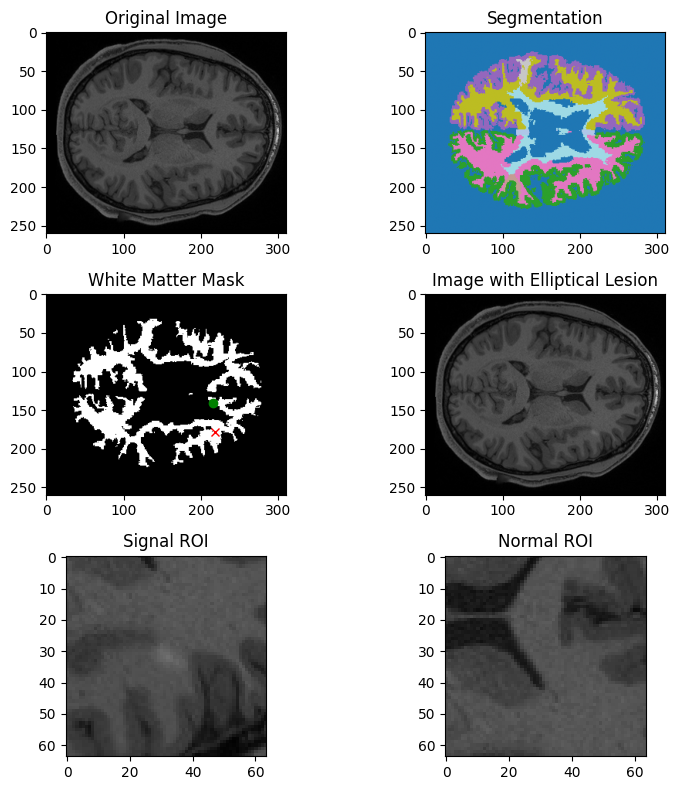

In [22]:
rng = np.random.default_rng(random_seed)

image_i = 0
image = images[image_i].copy()
wm_mask = get_white_matter_mask(segmentations[image_i]) & border_safe_mask
center_idx = sample_valid_center(wm_mask, rng)
lesion = build_elliptical_lesion(center_idx, preview_lesion_intensity)
image_with_lesion = image + lesion

normal_center_mask = get_normal_center_mask(wm_mask, center_idx)
normal_center_idx = sample_valid_center(normal_center_mask, rng)

lesion_patch = extract_patch(image_with_lesion, center_idx)
normal_patch = extract_patch(image_with_lesion, normal_center_idx)

print(
    f"Lesion center: {center_idx.tolist()}, intensity: {preview_lesion_intensity:.2f}, "
    f"sigma_x: {lesion_sigma_x}, sigma_y: {lesion_sigma_y}, theta: {lesion_theta_deg} deg"
 )
print(f"Configured intensity sweep: {lesion_intensity_cases}")
print(f"Lesion patch shape: {lesion_patch.shape}, normal patch shape: {normal_patch.shape}")

plt.figure(figsize=(8, 8))
plt.subplot(3, 2, 1)
plt.title("Original Image")
plt.imshow(image, cmap="gray")
plt.clim([0, 1])

plt.subplot(3, 2, 2)
plt.title("Segmentation")
plt.imshow(segmentations[image_i], cmap="tab20")

plt.subplot(3, 2, 3)
plt.title("White Matter Mask")
plt.imshow(wm_mask, cmap="gray")
plt.plot(center_idx[1], center_idx[0], "rx")
plt.plot(normal_center_idx[1], normal_center_idx[0], "go")

plt.subplot(3, 2, 4)
plt.title("Image with Elliptical Lesion")
plt.imshow(image_with_lesion, cmap="gray")
plt.clim([0, 1])

plt.subplot(3, 2, 5)
plt.imshow(lesion_patch, cmap="gray")
plt.title("Signal ROI")
plt.clim([0, 1])

plt.subplot(3, 2, 6)
plt.imshow(normal_patch, cmap="gray")
plt.title("Normal ROI")
plt.clim([0, 1])

plt.tight_layout()
plt.show()

In [23]:
n_batch_images = 500
n_batches = (n_case_images + n_batch_images - 1) // n_batch_images

output_dir = Path(".\\MRI").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

images_lesion_indices_filepath = output_dir / "images_lesion_indices.bin"
images_normal_indices_filepath = output_dir / "images_normal_indices.bin"
save_lesioned_image_volumes = True
preview_filepath = output_dir / "images_lesioned.bin"

def build_lesioned_volume_filepath(lesion_intensity):
    if np.isclose(lesion_intensity, preview_lesion_intensity):
        return preview_filepath
    return output_dir / f"images_lesioned_intensity_{lesion_intensity:.2f}.bin"

def open_output_file(filepath):
    if filepath.exists():
        filepath.unlink()
    return builtins.open(filepath, "wb")

images_lesioned_filepaths = {
    lesion_intensity: build_lesioned_volume_filepath(lesion_intensity)
    for lesion_intensity in lesion_intensity_cases
}

rng = np.random.default_rng(random_seed)
images_lesion_indices = np.zeros((n_case_images, 2), dtype=np.int16)
images_normal_indices = np.zeros((n_case_images, 2), dtype=np.int16)

writers = {}
if save_lesioned_image_volumes:
    writers = {
        lesion_intensity: open_output_file(filepath)
        for lesion_intensity, filepath in images_lesioned_filepaths.items()
    }

try:
    for batch_i in range(n_batches):
        batch_start = batch_i * n_batch_images
        batch_end = min((batch_i + 1) * n_batch_images, n_case_images)
        images_is = np.arange(batch_start, batch_end)

        batch_images_by_intensity = None
        if save_lesioned_image_volumes:
            batch_images = images[images_is].astype(np.float32, copy=True)
            batch_images_by_intensity = {
                lesion_intensity: batch_images.copy()
                for lesion_intensity in lesion_intensity_cases
            }

        for local_i, image_i in enumerate(images_is):
            wm_mask = get_white_matter_mask(segmentations[image_i]) & border_safe_mask
            center_idx = sample_valid_center(wm_mask, rng)
            images_lesion_indices[image_i] = center_idx

            normal_center_mask = get_normal_center_mask(wm_mask, center_idx)
            normal_center_idx = sample_valid_center(normal_center_mask, rng)
            images_normal_indices[image_i] = normal_center_idx

            if save_lesioned_image_volumes:
                for lesion_intensity in lesion_intensity_cases:
                    batch_images_by_intensity[lesion_intensity][local_i] += build_elliptical_lesion(
                        center_idx, lesion_intensity
                    )

        print(f"Batch {batch_i + 1}/{n_batches} done, storing ROI centers.")

        if save_lesioned_image_volumes:
            for lesion_intensity, batch_images in batch_images_by_intensity.items():
                batch_images.tofile(writers[lesion_intensity])
            print(f"Batch {batch_i + 1}/{n_batches} done, saved lesioned image volumes.")
finally:
    for writer in writers.values():
        writer.close()

with open_output_file(images_lesion_indices_filepath) as f:
    images_lesion_indices.tofile(f)
with open_output_file(images_normal_indices_filepath) as f:
    images_normal_indices.tofile(f)

print(f"Saved lesion centers to {images_lesion_indices_filepath}")
print(f"Saved normal centers to {images_normal_indices_filepath}")
if save_lesioned_image_volumes:
    print(f"Saved preview lesioned volume to {preview_filepath}")
    for lesion_intensity, filepath in images_lesioned_filepaths.items():
        if not np.isclose(lesion_intensity, preview_lesion_intensity):
            print(f"Saved lesioned volume ({lesion_intensity:.2f}) to {filepath}")

Batch 1/22 done, storing ROI centers.
Batch 1/22 done, saved lesioned image volumes.
Batch 2/22 done, storing ROI centers.
Batch 2/22 done, saved lesioned image volumes.
Batch 3/22 done, storing ROI centers.
Batch 3/22 done, saved lesioned image volumes.
Batch 4/22 done, storing ROI centers.
Batch 4/22 done, saved lesioned image volumes.
Batch 5/22 done, storing ROI centers.
Batch 5/22 done, saved lesioned image volumes.
Batch 6/22 done, storing ROI centers.
Batch 6/22 done, saved lesioned image volumes.
Batch 7/22 done, storing ROI centers.
Batch 7/22 done, saved lesioned image volumes.
Batch 8/22 done, storing ROI centers.
Batch 8/22 done, saved lesioned image volumes.
Batch 9/22 done, storing ROI centers.
Batch 9/22 done, saved lesioned image volumes.
Batch 10/22 done, storing ROI centers.
Batch 10/22 done, saved lesioned image volumes.
Batch 11/22 done, storing ROI centers.
Batch 11/22 done, saved lesioned image volumes.
Batch 12/22 done, storing ROI centers.
Batch 12/22 done, save